In [1]:
import os
import sys
import time

import joblib
import skfda
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from kneed import KneeLocator

sys.path.insert(0, '../../..') 
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs

TARGET_MOVEMENT = 'Pick'

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [4]:
group_array = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw']
sample_size = None

# Usar o TimeSeriesScalerMeanVariance para normalizar as séries temporais,
# mas sem escalar para zero média e unidade de variância (useScaler=False)
X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 4661.26it/s]

Shape of first series: (111, 9)


Shape of formatted series: (380, 241, 9)


## fPCA

In [5]:
print(f"\n--- A preparar dados para fPCA ({TARGET_MOVEMENT}) ---")

# 1. Extrair as coordenadas da mão (n_samples, n_timepoints, 3)
X_hand = X_movement[:, :, 6:9].copy() # .copy() para não alterar o array original

# 2. LIMPEZA DE NaNs (Forward Fill)
# Vamos percorrer cada amostra e cada eixo (X, Y, Z) e estender o último valor válido
for i in range(X_hand.shape[0]):
    for j in range(X_hand.shape[2]):
        # Usamos o Pandas temporariamente porque ele tem a melhor função de preenchimento
        s = pd.Series(X_hand[i, :, j])
        # ffill() preenche para a frente, bfill() garante que se houver NaNs no início também são tratados
        X_hand[i, :, j] = s.ffill().bfill().values

# 3. O Truque da Concatenação (Esmagar para 2D)
n_samples, n_timepoints, n_dims = X_hand.shape
X_hand_concat = np.transpose(X_hand, (0, 2, 1)).reshape(n_samples, n_timepoints * n_dims)

time_points_concat = np.arange(X_hand_concat.shape[1])

# 4. Converter para o formato FDataGrid do scikit-fda (Agora sem NaNs!)
fd = skfda.FDataGrid(data_matrix=X_hand_concat, grid_points=time_points_concat)


--- A preparar dados para fPCA (Pick) ---


In [6]:
# --- APLICAR O fPCA ---

start_time_fpca = time.perf_counter()

n_components = 5 
fpca = PCA(n_components=n_components)

fpc_scores = fpca.fit_transform(fd)

end_time_fpca = time.perf_counter()
print(f"fPCA concluído em {end_time_fpca - start_time_fpca:.4f} segundos!")
print(f"Variância explicada pelos {n_components} componentes: {sum(fpca.explained_variance_ratio_):.2%}")

ValueError: setting an array element with a sequence.

In [ ]:
# =========================================================================
# 1. PREPARAÇÃO DIRETA (E sem alucinações desta vez!)
# =========================================================================
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()
results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)

# Verificar integridade
if len(results_temp_base) != fpc_scores.shape[0]:
    print("⚠️ AVISO: Metadados não batem certo com o número de scores fPCA!")

total_trials_unique = df_filtered.drop_duplicates(subset=['sub', 'repID'])
total_trials = len(total_trials_unique)

known_outlier_rate = total_known_outliers / total_trials
percentagem_conhecida = known_outlier_rate * 100

print(f"Total de repetições únicas analisadas ({TARGET_MOVEMENT}): {total_trials}")
print(f"Taxa mínima confirmada de outliers no CSV: {percentagem_conhecida:.2f}%")

Total de repetições únicas analisadas (Pick): 95
Taxa mínima confirmada de outliers no CSV: 14.74%



A calcular distâncias para o 4º vizinho nos scores fPCA...
A detetar o ponto de cotovelo (EPS ideal)...
Valor matemático do EPS (Cotovelo): 1055.8737980228848


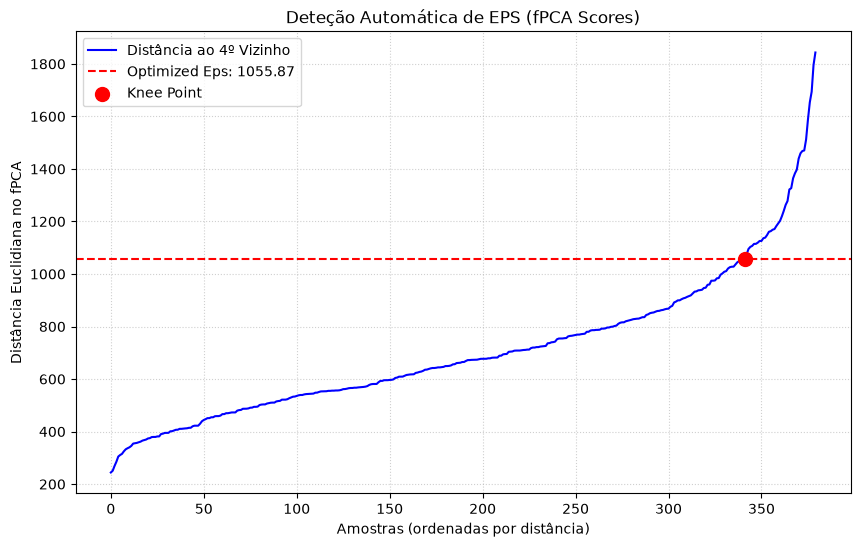

In [ ]:
# =========================================================================
# 2. O LINK PERDIDO: Cálculo de Distâncias e Kneedle para fPCA
# =========================================================================
k = 4 # Min samples heurístico para arrancar

print(f"\nA calcular distâncias para o {k}º vizinho nos scores fPCA...")
# ATENÇÃO: Retirámos o metric='precomputed'. Agora ele calcula a distância no espaço fPCA.
nbrs = NearestNeighbors(n_neighbors=k) 
nbrs.fit(fpc_scores)

distances, indices = nbrs.kneighbors(fpc_scores)

# Distância para o k-ésimo vizinho (coluna k-1) e ordenação
k_distances = np.sort(distances[:, k-1])

print("A detetar o ponto de cotovelo (EPS ideal)...")
x = range(len(k_distances))

# Configuração vital do Kneedle para curvas de distância
kneedle = KneeLocator(x, k_distances, curve='convex', direction='increasing')
optimal_eps = kneedle.elbow_y

print(f"Valor matemático do EPS (Cotovelo): {optimal_eps}")

# --- PLOT DO COTOVELO ---
plt.figure(figsize=(10, 6))
plt.plot(x, k_distances, label=f'Distância ao {k}º Vizinho', color='blue', linewidth=1.5)

if optimal_eps is not None:
    plt.axhline(y=optimal_eps, color='r', linestyle='--', label=f'Optimized Eps: {optimal_eps:.2f}')
    plt.scatter([kneedle.elbow], [optimal_eps], color='red', s=100, zorder=5, label='Knee Point')
else:
    print("Aviso: O algoritmo não encontrou um cotovelo claro. Verifica o gráfico.")

plt.title(f'Deteção Automática de EPS (fPCA Scores)')
plt.xlabel('Amostras (ordenadas por distância)')
plt.ylabel('Distância Euclidiana no fPCA')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [ ]:
# =========================================================================
# 3. GRID SEARCH DINÂMICO (À Volta do Cotovelo)
# =========================================================================
min_samples_options = [3, 4, 5, 7, 10]

# Estratégia Híbrida: Procurar 15% abaixo e 15% acima do valor do Kneedle
if optimal_eps is not None:
    eps_min = optimal_eps * 0.85
    eps_max = optimal_eps * 1.15
else:
    eps_min, eps_max = 0.1, 2.0 # Fallback de segurança

eps_options = [round(e, 3) for e in np.linspace(eps_min, eps_max, 20)]

results_log = []
print("\n--- A iniciar Grid Search (DBSCAN + fPCA) ---")

for m_samp in min_samples_options:
    for eps_val in eps_options:
        
        # TREINO DO DBSCAN (Sem 'precomputed', usa a métrica padrão)
        model = DBSCAN(eps=eps_val, min_samples=m_samp)
        labels = model.fit_predict(fpc_scores)
        
        # --- CÁLCULO DE MÉTRICAS ---
        results_temp = results_temp_base.copy()
        results_temp['label'] = labels
        
        real_outliers_info = results_temp[results_temp['label'] == -1]
        identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])
        
        matched = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')
        missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
        
        TP = len(matched)
        FP = len(identified_unique) - TP
        FN = len(missing_outliers[missing_outliers['_merge'] == 'left_only'])
        
        recall = (TP / total_known_outliers) * 100 if total_known_outliers > 0 else 0
        precision = (TP / (TP + FP)) * 100 if (TP + FP) > 0 else 0
        
        if (precision + recall) > 0:
            f1_score = 2 * (precision * recall) / (precision + recall)
            f2_score = 5 * (precision * recall) / (4 * precision + recall) if (4 * precision + recall) > 0 else 0
        else:
            f1_score, f2_score = 0.0, 0.0
            
        results_log.append({
            'min_samples': m_samp,
            'eps': eps_val,
            'Recall': recall,
            'Precision': precision,
            'F1-Score': f1_score,
            'F2-Score': f2_score,
            'TP': TP,
            'FP': FP,
            'FN': FN,
            'Percentagem Lixo': (len(identified_unique) / total_trials) * 100 
        })


--- A iniciar Grid Search (DBSCAN + fPCA) ---


In [ ]:
# =========================================================================
# SELEÇÃO DO MELHOR MODELO
# =========================================================================
results_df = pd.DataFrame(results_log)
limite_lixo = percentagem_conhecida + 5.0 

acceptable_models = results_df[results_df['Percentagem Lixo'] <= limite_lixo]

if acceptable_models.empty:
    print(f"⚠️ Aviso: Nenhum modelo conseguiu ter menos de {limite_lixo:.1f}% de lixo.")
    acceptable_models = results_df

best_results = acceptable_models.sort_values(by=['Recall', 'F2-Score'], ascending=False)

print(f"\nTOP 5 CONFIGURAÇÕES (DBSCAN + fPCA): Limite Lixo={limite_lixo:.1f}%")
print(best_results[['min_samples', 'eps', 'Percentagem Lixo', 'Recall', 'Precision', 'F1-Score']].head(5))

best_params = best_results.iloc[0]

print(f"\n🏆 VENCEDOR DO GRID SEARCH (DBSCAN + fPCA):")
print(f"Min Samples: {best_params['min_samples']}")
print(f"Epsilon (Eps): {best_params['eps']}")
print(f"F2-Score: {best_params['F2-Score']:.2f}% | Lixo: {best_params['Percentagem Lixo']:.2f}%")
print(f"TP: {best_params['TP']} | FP: {best_params['FP']} | FN: {best_params['FN']}")


TOP 5 CONFIGURAÇÕES (DBSCAN + fPCA): Limite Lixo=19.7%
    min_samples       eps  Percentagem Lixo     Recall  Precision   F1-Score
50            5  1064.210         17.894737  42.857143  35.294118  38.709677
76            7  1164.240         18.947368  42.857143  33.333333  37.500000
77            7  1180.911         18.947368  42.857143  33.333333  37.500000
78            7  1197.583         18.947368  42.857143  33.333333  37.500000
31            4  1080.881         15.789474  35.714286  33.333333  34.482759

🏆 VENCEDOR DO GRID SEARCH (DBSCAN + fPCA):
Min Samples: 5.0
Epsilon (Eps): 1064.21
F2-Score: 41.10% | Lixo: 17.89%
TP: 6.0 | FP: 11.0 | FN: 8.0
